# 🛡️ Итгэлцлийн оноо — скоркарт загвар (төслийн баримт бичгийн дагуу)
**Юу хийх вэ** (баримт бичгийн «Өгөгдөл ба загвар сургах» хэсэг):
1. Текстээс **тайлбарлагдахуйц шинж тэмдэг** (clickbait, сэтгэл хөдлөл, нэргүй эх сурвалж, том үсэг, «!»…) тооцно
2. TF-IDF+LR текст ангилагчийн оноог нэг шинж болгож нэмнэ
3. **LightGBM + monotonic constraint** — шинж бүрийн чиглэлийг (−/+) шинжээч урьдчилан тогтооно
4. Калибровк → **Итгэлцлийн оноо 0–100**: 🟢 70+, 🟡 40–69, 🔴 <40
5. **SHAP**-аар гол 3 шалтгаан (reason code)
6. Үнэлгээ: macro F1, **бодит мэдээ улаан бүсэд орсон хувь** (хамгийн чухал), ECE, хэцүү тест, сайт тус бүрийг нууж шалгах

Домэйн модулийг (цагаан жагсаалт, дуурайсан нэр, HTTPS) өгөгдлөөр сургах боломжгүй тул баримт бичгийн дагуу **шинжээчийн жингээр** нэмнэ (9-р алхам).

In [1]:
# !pip install -q lightgbm scikit-learn pandas matplotlib joblib
import re, joblib, numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, roc_auc_score, classification_report

PREFIX = "HACKMIL_dataset_v31_"          # ← файлын нэрийн эхлэл
train, val, test = (pd.read_csv(f"{PREFIX}{s}.csv") for s in ("train", "val", "test"))
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s}: {len(d):4d} | үнэн {(d.label==0).sum():4d} | худал {(d.label==1).sum():4d}")

train: 2534 | үнэн  843 | худал 1691
val  :  286 | үнэн   88 | худал  198
test :  287 | үнэн   89 | худал  198


## 1. Шинж тэмдгүүд (скоркартын «Текст» бүлэг)
`+1` = эрсдэл нэмнэ (итгэлцэл бууруулна), `-1` = итгэлцэл нэмнэ, `0` = чиглэл тогтоохгүй.
`reason` нь хэрэглэгчид харагдах тайлбар, `card` нь MIL картын гарчиг.

In [2]:
SIGNALS = {  # нэр: (regex, чиглэл, reason, MIL карт)
    "clickbait":     (r"шок\b|итгэхгүй|гайхмаар|хараарай|үзээрэй|нууц нь|цочирдм", +1, "Clickbait хэллэг", "Clickbait гарчиг яагаад аюултай вэ?"),
    "emotion":       (r"аймшиг|айхтар|гамшиг|үхэл|үхүүл|аюул|харамсалтай|эмгэнэл|эмзэглүүл|сүйрэл|айдас", +1, "Айдас, сэтгэл хөдлөл өдөөсөн үг", "Сэтгэл хөдлөл шүүлтийг яаж халхалдаг вэ?"),
    "urgency":       (r"яаралтай|шэйр|шейр|хуваалцаарай|тараа(рай|гаарай)|амжаарай|устгагдах", +1, "Яаруулж, тараахыг шаардсан", "«Яаралтай шэйрлээрэй» гэвэл яагаад зогсох вэ?"),
    "absolute":      (r"100\s?%|бүрэн эдгэр|хэзээ ч|ганцхан|гайхамшиг|шидэт|баталгаатай", +1, "Хэтрүүлсэн, туйлширсан амлалт", "«100% эдгэрнэ» гэдэгт яагаад эргэлзэх вэ?"),
    "conspiracy":    (r"нууж|нуудаг|нууцал|биднээс|хуйвалд|далд|сэрээрэй", +1, "Хуйвалдааны хэллэг", "«Тэд нууж байна» хэллэгийг таних"),
    "anon_source":   (r"эрдэмтэд|судлаачид|эмч нар|гэнэ\b|гэнээ|гэсэн байна|эх сурвалжийн мэдээлснээр|сонссон", +1, "Нэргүй эсвэл тодорхойгүй эх сурвалж", "Яагаад нэргүй эх сурвалжаас болгоомжлох вэ?"),
    "scam":          (r"линк|дарж|хожсон|хонжвор|бэлэг|данс|картын|урамшуулал|үнэгүй ав|дугаараа", +1, "Луйврын урхины шинж", "Цахим луйврыг яаж таних вэ?"),
    "call_to_action":(r"(аарай|ээрэй|оорой|өөрэй)\b", +1, "Үйлдэл хийхийг шаардсан", "Яагаад «хуваалц», «дар» гэж шахдаг вэ?"),
    "named_source":  (r"яам|газар|хороо|агентлаг|хүрээлэн|мэдээлснээр|мэдэгдэв|мэдээллээ|тогтоол|засгийн газ|уих|их хурал|шүүх|цагдаа", -1, "Нэр бүхий байгууллагад эш татсан", "Эх сурвалжийг яаж шалгах вэ?"),
}
EXTRA = {  # тоон шинжүүд: (чиглэл, reason, илэрсэн гэж тооцох босго)
    "caps":         (+1, "Том үсэг хэт олон", 0.30),
    "exclaim":      (+1, "Анхаарлын тэмдэг хэт олон", 2),
    "question":     (+1, "Риторик асуулт", 2),
    "emoji":        (+1, "Emoji хэт олон", 2),
    "named_person": (-1, "Нэр бүхий хүнд эш татсан", 1),
    "numbers":      (0, None, None),
    "n_words":      (0, None, None),
}
EMOJI = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
INITIALS = re.compile(r"\b[А-ЯЁӨҮ]\.[А-ЯЁӨҮ][а-яёөү]+")      # «Н.Учрал» гэх мэт

def signals(texts):
    rows = []
    for t in texts:
        t = str(t); low = t.lower(); n = max(len(t), 1)
        r = {k: len(re.findall(v[0], low)) for k, v in SIGNALS.items()}
        r.update(caps=sum(c.isupper() for c in t) / n, exclaim=t.count("!"), question=t.count("?"),
                 emoji=len(EMOJI.findall(t)), named_person=len(INITIALS.findall(t)),
                 numbers=len(re.findall(r"\d", t)) / n, n_words=len(t.split()))
        rows.append(r)
    return pd.DataFrame(rows)

S_train, S_val, S_test = signals(train.text), signals(val.text), signals(test.text)
print("Шинж бүрийн дундаж (0 = үнэн, 1 = худал):")
S_train.assign(label=train.label).groupby("label").mean().T.round(3)

Шинж бүрийн дундаж (0 = үнэн, 1 = худал):


label,0,1
clickbait,0.002,0.004
emotion,0.037,0.041
urgency,0.001,0.018
absolute,0.001,0.012
conspiracy,0.039,0.024
anon_source,0.027,0.072
scam,0.009,0.049
call_to_action,0.034,0.066
named_source,0.552,0.102
caps,0.035,0.050


## 2. Текст ангилагчийн оноог шинж болгох
Train дээрх оноог **out-of-fold** (5 хэсэгт хувааж, мөр бүрийг өөрийг нь хараагүй загвараар) тооцно.
Тэгэхгүй бол LightGBM «цээжилсэн» оноог харж leakage болно. `pair_id`-аар бүлэглэнэ.

In [3]:
def text_model():
    return Pipeline([("tf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=200000)),
                     ("lr", LogisticRegression(max_iter=3000, class_weight="balanced", C=2.0))])

S_train["text_model"] = cross_val_predict(text_model(), train.text, train.label, cv=GroupKFold(5),
                                          groups=train.pair_id, method="predict_proba")[:, 1]
tm = text_model().fit(train.text, train.label)
S_val["text_model"] = tm.predict_proba(val.text)[:, 1]
S_test["text_model"] = tm.predict_proba(test.text)[:, 1]
print("OK")

OK


## 3. LightGBM + monotonic constraint
3 хувилбарыг **val** дээр харьцуулна: зөвхөн шинж тэмдэг / зөвхөн текст ангилагч / хоёулаа.

In [4]:
MONO = {**{k: v[1] for k, v in SIGNALS.items()}, **{k: v[0] for k, v in EXTRA.items()}, "text_model": +1}
SIG_COLS = list(SIGNALS) + list(EXTRA)

def lgbm(cols):
    return lgb.LGBMClassifier(objective="binary", learning_rate=0.05, num_leaves=15, min_child_samples=20,
                              n_estimators=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              monotone_constraints=[MONO[c] for c in cols], is_unbalance=True, verbose=-1, random_state=42)

def evaluate(name, y, p):
    trust = 100 * (1 - p)
    red_true = ((trust < 40) & (y == 0)).sum() / (y == 0).sum()      # бодит мэдээ улаан бүсэд
    green_false = ((trust >= 70) & (y == 1)).sum() / (y == 1).sum()  # худал мэдээ ногоон бүсэд
    print(f"{name:30s} macroF1={f1_score(y, p >= .5, average='macro'):.3f}  AUC={roc_auc_score(y, p):.3f}  "
          f"үнэн→🔴 {red_true:5.1%}  худал→🟢 {green_false:5.1%}")

for name, cols in [("Зөвхөн шинж тэмдэг", SIG_COLS), ("Зөвхөн текст ангилагч", ["text_model"]),
                   ("Шинж тэмдэг + текст ангилагч", SIG_COLS + ["text_model"])]:
    m = lgbm(cols).fit(S_train[cols], train.label)
    evaluate(name + " (val)", val.label.values, m.predict_proba(S_val[cols])[:, 1])

Зөвхөн шинж тэмдэг (val)       macroF1=0.670  AUC=0.800  үнэн→🔴 22.7%  худал→🟢 10.6%
Зөвхөн текст ангилагч (val)    macroF1=0.924  AUC=0.982  үнэн→🔴  3.4%  худал→🟢  4.5%
Шинж тэмдэг + текст ангилагч (val) macroF1=0.911  AUC=0.976  үнэн→🔴  5.7%  худал→🟢  4.5%


**Унших нь:** «Зөвхөн шинж тэмдэг» сул (тайлбарлагдахуйц ч агуулгыг хардаггүй).
Хослуулсан хувилбар нь өндөр нарийвчлалтай + шалтгааныг шинж тэмдгээр тайлбарлана → **үүнийг сонгоно**.

## 4. Калибровк ба итгэлцлийн оноо
`CalibratedClassifierCV` нь магадлалыг бодит утгатай болгоно. **Итгэлцлийн оноо = 100 × (1 − худал байх магадлал)**.

In [5]:
COLS = SIG_COLS + ["text_model"]
model = CalibratedClassifierCV(lgbm(COLS), method="isotonic", cv=5).fit(S_train[COLS], train.label)

def zone(trust):
    return "🟢 ногоон" if trust >= 70 else ("🟡 шар" if trust >= 40 else "🔴 улаан")

p_val = model.predict_proba(S_val[COLS])[:, 1]
evaluate("Калибровктой загвар (val)", val.label.values, p_val)

Калибровктой загвар (val)      macroF1=0.917  AUC=0.976  үнэн→🔴 13.6%  худал→🟢  1.0%


## 5. ⚠️ TEST — ганц удаа
Хамгийн чухал тоо: **үнэн→🔴** (бодит мэдээг улаан бүсэд оруулсан хувь).

In [6]:
p_test = model.predict_proba(S_test[COLS])[:, 1]
evaluate("TEST", test.label.values, p_test)
print(classification_report(test.label, p_test >= .5, target_names=["үнэн", "худал"], digits=3))

t = test.assign(trust=100 * (1 - p_test))
t["бүс"] = t.trust.map(zone)
print(pd.crosstab(t.label.map({0: "үнэн", 1: "худал"}), t["бүс"]))

TEST                           macroF1=0.948  AUC=0.985  үнэн→🔴  5.6%  худал→🟢  2.0%
              precision    recall  f1-score   support

        үнэн      0.913     0.944     0.928        89
       худал      0.974     0.960     0.967       198

    accuracy                          0.955       287
   macro avg      0.944     0.952     0.948       287
weighted avg      0.955     0.955     0.955       287

бүс    🔴 улаан  🟡 шар  🟢 ногоон
label                          
худал      183     11         4
үнэн         5      4        80


### Калибровк (ECE ба reliability diagram)
ECE бага байх тусам «оноо 80» гэдэг нь үнэхээр ~80% гэсэн үг.

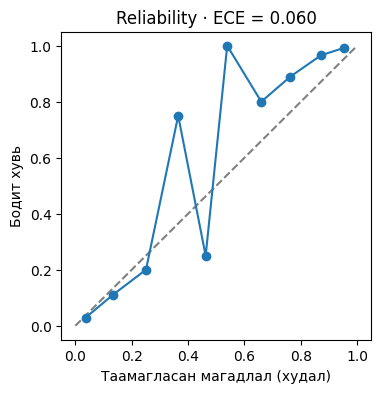

In [7]:
def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e = 0
    xs, ys = [], []
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(p[m].mean() - y[m].mean()); xs.append(p[m].mean()); ys.append(y[m].mean())
    return e, xs, ys

e, xs, ys = ece(test.label.values, p_test)
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", c="gray"); plt.plot(xs, ys, "o-")
plt.xlabel("Таамагласан магадлал (худал)"); plt.ylabel("Бодит хувь"); plt.title(f"Reliability · ECE = {e:.3f}"); plt.show()

## 6. Хэцүү тест (баримт бичгийн 8-р хэсэг)
Энгийн test ба хэцүү тестийн **зөрүү** — загвар хэв маягаар хуурагдаж байгаа эсэхийн хэмжүүр.

In [9]:
PROBES = [  # (бүлэг, зөв хариу 0=үнэн 1=худал, текст) — багаараа нэмээрэй
    ("A үнэн+ярианы", 0, "Маргаашнаас гэр хорооллынхны цахилгааны шөнийн тариф хямдарна шүү, мэдээрэй!"),
    ("A үнэн+ярианы", 0, "Хүүхдээ эрт илрүүлгийн үзлэгт хамруулаарай, сургууль цэцэрлэг дээр нь үнэгүй хийж байгаа юм билээ"),
    ("A үнэн+ярианы", 0, "Сурагчид ирэх долоо хоногт хичээллээд дараа нь амарна гэнэ ээ"),
    ("A үнэн+ярианы", 0, "Зуны дугуйтай явж болохгүй шүү, зам их халтиргаатай байна. Өвлийн дугуйгаа сольцгоо"),
    ("A үнэн+ярианы", 0, "Налайх орчимд баавгай үзэгдсэн гэнэ, гадуур явахдаа болгоомжтой байгаарай"),
    ("B худал+албан", 1, "Эрүүл мэндийн яамнаас мэдээлснээр сод уусгасан ус өдөр бүр уухад хорт хавдар бүрэн эдгэрдэг болох нь тогтоогджээ"),
    ("B худал+албан", 1, "Засгийн газрын хуралдаанаар 2027 оноос эхлэн иргэн бүрийн хадгаламжийн 30 хувийг төрд шилжүүлэх шийдвэр гаргалаа"),
    ("B худал+албан", 1, "Монголбанкны ерөнхийлөгч ирэх сарын 1-нээс төгрөгийн бүх дэвсгэртийг хүчингүй болгохыг мэдэгдэв"),
    ("B худал+албан", 1, "УИХ-ын чуулганы хуралдаанаар Монгол Улс цөмийн хог хаягдал хүлээн авах гэрээг соёрхон баталлаа"),
    ("B худал+албан", 1, "ДЭМБ-аас гаргасан судалгаагаар ковидын вакцин хийлгэсэн хүмүүсийн 40 хувь нь үргүйдсэн байна"),
    ("C худал+манипуляц", 1, "ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 3 хоногт чихрийн шижин 100% эдгэрнэ, ШЭЙРЛЭЭРЭЙ"),
    ("C худал+манипуляц", 1, "Банкнаас 500,000 төгрөгийн бэлэг хожсон байна, линк дээр дарж картын дугаараа баталгаажуулаарай"),
    ("C худал+манипуляц", 1, "Тэд биднээс нууж байна. Вакцин дотор чип суулгаад бүгдийг хянаж байгаа, сэрээрэй монголчууд аа"),
    ("D үнэн+албан", 0, "УИХ-ын намрын ээлжит чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлцэх эсэхийг шийдвэрлэлээ"),
    ("D үнэн+албан", 0, "Нийслэлийн Засаг дарга иргэдийн газар өмчлөх ажлыг эрчимжүүлэх үүрэг даалгавар өглөө"),
    ("D үнэн+албан", 0, "Ой, хээрийн түймрийн тохиолдол өмнөх оны мөн үетэй харьцуулахад 29 хувиар буурсан байна"),
]
pr = pd.DataFrame(PROBES, columns=["бүлэг", "зөв", "текст"])
Sp = signals(pr["текст"]); Sp["text_model"] = tm.predict_proba(pr["текст"])[:, 1]
pr["итгэлцэл"] = (100 * (1 - model.predict_proba(Sp[COLS])[:, 1])).round()
pr["бүс"] = pr["итгэлцэл"].map(zone)
# зөв гэж тооцох: үнэн → 🔴 биш, худал → 🟢 биш
pr["зөв таасан"] = np.where(pr["зөв"] == 0, pr["итгэлцэл"] >= 40, pr["итгэлцэл"] < 70)
print(pr.groupby("бүлэг")["зөв таасан"].agg(["sum", "count"]))
print(f"\nХэцүү тест: {pr['зөв таасан'].mean():.0%}  vs  энгийн test: {((p_test >= .5) == test.label).mean():.0%}")
pr[["бүлэг", "итгэлцэл", "бүс", "текст"]]

                   sum  count
бүлэг                        
A үнэн+ярианы        1      5
B худал+албан        3      5
C худал+манипуляц    3      3
D үнэн+албан         3      3

Хэцүү тест: 62%  vs  энгийн test: 95%


,бүлэг,итгэлцэл,бүс,текст
0,A үнэн+ярианы,14.0,🔴 улаан,Маргаашнаас гэр хорооллынхны цахилгааны шөнийн...
1,A үнэн+ярианы,34.0,🔴 улаан,"Хүүхдээ эрт илрүүлгийн үзлэгт хамруулаарай, су..."
2,A үнэн+ярианы,5.0,🔴 улаан,Сурагчид ирэх долоо хоногт хичээллээд дараа нь...
3,A үнэн+ярианы,44.0,🟡 шар,"Зуны дугуйтай явж болохгүй шүү, зам их халтирг..."
4,A үнэн+ярианы,10.0,🔴 улаан,"Налайх орчимд баавгай үзэгдсэн гэнэ, гадуур яв..."
5,B худал+албан,28.0,🔴 улаан,Эрүүл мэндийн яамнаас мэдээлснээр сод уусгасан...
6,B худал+албан,94.0,🟢 ногоон,Засгийн газрын хуралдаанаар 2027 оноос эхлэн и...
7,B худал+албан,15.0,🔴 улаан,Монголбанкны ерөнхийлөгч ирэх сарын 1-нээс төг...
8,B худал+албан,94.0,🟢 ногоон,УИХ-ын чуулганы хуралдаанаар Монгол Улс цөмийн...
9,B худал+албан,3.0,🔴 улаан,ДЭМБ-аас гаргасан судалгаагаар ковидын вакцин ...


## 7. Сайтыг бүхэлд нь нууж шалгах (баримт бичгийн «домэйнээр хуваах»)
Нэг мэдээний сайтыг сургалтаас бүрэн хасаад, тэр сайтын мэдээг хэдэн хувь нь улаан бүсэд орж байгааг харна.
Загвар **урьд нь хараагүй** найдвартай сайт дээр ажиллах уу гэдгийг шалгана.

In [10]:
full = pd.concat([train, val, test], ignore_index=True)
S_full = signals(full.text)
for site in ["ikon", "gogo", "eagle"]:
    tr_m = (full.platform != site) & (full.split == "train")
    tmx = text_model().fit(full.text[tr_m], full.label[tr_m])
    St = S_full[tr_m].copy()
    St["text_model"] = cross_val_predict(text_model(), full.text[tr_m], full.label[tr_m], cv=GroupKFold(5),
                                         groups=full.pair_id[tr_m], method="predict_proba")[:, 1]
    mx = lgbm(COLS).fit(St[COLS], full.label[tr_m])
    held = full.platform == site
    Sh = S_full[held].copy(); Sh["text_model"] = tmx.predict_proba(full.text[held])[:, 1]
    trust = 100 * (1 - mx.predict_proba(Sh[COLS])[:, 1])
    print(f"{site:6s}: {held.sum():3d} мэдээ (сургалтад огт ороогүй) → 🔴 {(trust < 40).mean():5.1%}  🟡 {((trust >= 40) & (trust < 70)).mean():5.1%}  🟢 {(trust >= 70).mean():5.1%}")

ikon  : 277 мэдээ (сургалтад огт ороогүй) → 🔴  7.2%  🟡  3.2%  🟢 89.5%
gogo  : 273 мэдээ (сургалтад огт ороогүй) → 🔴  6.2%  🟡  4.0%  🟢 89.7%
eagle : 285 мэдээ (сургалтад огт ороогүй) → 🔴  7.7%  🟡  5.3%  🟢 87.0%


## 8. SHAP шалтгаан (reason codes)
LightGBM-ийн TreeSHAP (`pred_contrib=True`) нь шинж бүр оноог хэр хөдөлгөснийг гаргана.
Зөвхөн **үнэхээр илэрсэн** шинжийг шалтгаан болгоно.

In [11]:
explainer = lgbm(COLS).fit(S_train[COLS], train.label)    # калибровкгүй ижил загвар — тайлбарт

def reasons(S_row):
    contrib = explainer.booster_.predict(S_row[COLS], pred_contrib=True)[0][:-1]   # сүүлийнх = bias
    minus, plus = [], []
    for i in np.argsort(-np.abs(contrib)):
        f, c, v = COLS[i], contrib[i], S_row[COLS[i]].iloc[0]
        if f in SIGNALS:
            fired, text = v > 0, SIGNALS[f][2]
        elif f in EXTRA and EXTRA[f][1]:
            fired, text = v >= EXTRA[f][2], EXTRA[f][1]
        elif f == "text_model":
            fired, text = True, ("Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй" if c > 0 else "Бичлэгийн хэв маяг мэдээллийн сайттай төстэй")
        else:
            continue
        if not fired:
            continue
        # Шинжээчийн тогтоосон чиглэлтэй зөрчилдөх шалтгааныг харуулахгүй (жишээ нь «яаруулсан» нь итгэлцлийн дохио болохгүй)
        if c > 0 and MONO[f] >= 0:
            minus.append(text)
        elif c < 0 and MONO[f] <= 0:
            plus.append(text)
        elif f == "text_model":
            (minus if c > 0 else plus).append(text)
    return minus[:3], plus[:2]

## 9. `trust_score()` — эцсийн функц (текст + домэйн)
Домэйн модуль нь **шинжээчийн жин**тэй дүрэм (баримт бичгийн дагуу) — өгөгдлөөр сургаагүй.

In [12]:
WHITELIST = ["ikon.mn", "gogo.mn", "eagle.mn", "news.mn", "montsame.mn", "unuudur.mn", "isee.mn", "bolod.mn", "24tsag.mn"]

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def domain_adjust(url):
    # Шинжээчийн жин: цагаан жагсаалт +10, дуурайсан нэр −30, HTTPS байхгүй −10
    if not url:
        return 0, []
    host = re.sub(r"^https?://(www\.)?", "", url.lower()).split("/")[0]
    if host in WHITELIST:
        return +10, ["+ Бүртгэлтэй хэвлэл мэдээллийн байгууллага"]
    adj, why = 0, []
    if any(0 < levenshtein(host, w) <= 2 for w in WHITELIST):
        adj -= 30; why.append("− Алдартай мэдээллийн сайтыг дуурайсан домэйн нэр")
    if url.lower().startswith("http://"):
        adj -= 10; why.append("− HTTPS байхгүй")
    return adj, why

def trust_score(text, url=None):
    S = signals([text]); S["text_model"] = tm.predict_proba([text])[:, 1]
    trust = 100 * (1 - model.predict_proba(S[COLS])[0, 1])
    d_adj, d_why = domain_adjust(url)
    trust = float(np.clip(trust + d_adj, 0, 100))
    minus, plus = reasons(S)
    minus = [m for m in minus][:3]
    return {"итгэлцэл": round(trust), "бүс": zone(trust),
            "эрсдэлийн шалтгаан": minus + [w for w in d_why if w.startswith("−")],
            "итгэлцлийн дохио": plus + [w for w in d_why if w.startswith("+")]}

for txt, url in [("ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 100% эдгэрнэ, шэйрлээрэй", None),
                 ("УИХ-ын чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлцэв", "https://ikon.mn/n/3r93"),
                 ("Банкнаас бэлэг хожсон байна, линк дээр дарж аваарай", "http://ik0n.mn/promo")]:
    print(trust_score(txt, url), "\n   ←", txt[:60], "\n")

{'итгэлцэл': 0, 'бүс': '🔴 улаан', 'эрсдэлийн шалтгаан': ['Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй', 'Анхаарлын тэмдэг хэт олон', 'Нэргүй эсвэл тодорхойгүй эх сурвалж'], 'итгэлцлийн дохио': []} 
   ← ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 100% эдгэрнэ, шэй 

{'итгэлцэл': 100, 'бүс': '🟢 ногоон', 'эрсдэлийн шалтгаан': [], 'итгэлцлийн дохио': ['Бичлэгийн хэв маяг мэдээллийн сайттай төстэй', 'Нэр бүхий байгууллагад эш татсан', '+ Бүртгэлтэй хэвлэл мэдээллийн байгууллага']} 
   ← УИХ-ын чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлц 

{'итгэлцэл': 0, 'бүс': '🔴 улаан', 'эрсдэлийн шалтгаан': ['Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй', 'Луйврын урхины шинж', '− Алдартай мэдээллийн сайтыг дуурайсан домэйн нэр', '− HTTPS байхгүй'], 'итгэлцлийн дохио': []} 
   ← Банкнаас бэлэг хожсон байна, линк дээр дарж аваарай 



## 10. Хадгалах
Backend-д `hackmil_scorecard.joblib`-ийг ачаалахын өмнө 1, 8, 9-р алхмын функцуудыг (`signals`, `reasons`, `trust_score`…) тодорхойлсон байх ёстой.

In [13]:
joblib.dump({"model": model, "explainer": explainer, "text_model": tm, "cols": COLS,
             "signals": SIGNALS, "extra": EXTRA, "whitelist": WHITELIST}, "hackmil_scorecard.joblib")
print("💾 hackmil_scorecard.joblib хадгаллаа")

💾 hackmil_scorecard.joblib хадгаллаа
